In [1]:
import pandas as pd
import requests
from collections import Counter
from functools import lru_cache
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")


DATA_DIR = Path(".").resolve() / "motrpac_exercise"

# scientific notation
pd.set_option('display.float_format', '{:.2e}'.format)

In [2]:
drug_lookup = pd.read_json('/Users/MaayanLab/GitHub/PerturbSeqr/public/metadata/drug_lookup.json')

## Query Functions

In [3]:
def enrich_perturbseqr_up_down(genes_up: list[str], genes_down: list[str], first=1000):
  url = "https://perturbseqr.maayanlab.cloud/graphql"
  query = {
    "operationName": "PairEnrichmentQuery",
    "variables": {
      "filterTerm": "",
      "offset": 0,
      "first": first,
      "filterFda": False,
      "sortBy": "pvalue_mimic",
      "filterKo": False,
      "topN": first,
      "pvalueLe": 0.05,
      "genesUp": genes_up,
      "genesDown": genes_down
    },
    "query": """query PairEnrichmentQuery($genesUp: [String]!, $genesDown: [String]!, $filterTerm: String = \"\", $offset: Int = 0, $first: Int = 10, $filterFda: Boolean = false, $sortBy: String = \"\", $filterKo: Boolean = false, $topN: Int = 10000, $pvalueLe: Float = 0.05) {
      currentBackground {
        pairedEnrich(
          filterTerm: $filterTerm
          offset: $offset
          first: $first
          filterFda: $filterFda
          sortby: $sortBy
          filterKo: $filterKo
          topN: $topN
          pvalueLe: $pvalueLe
          genesDown: $genesDown
          genesUp: $genesUp
          ) {
            totalCount
            consensusCount
            consensus {
              drug
              oddsRatio
              pvalue
              adjPvalue
              approved
              countSignificant
              countInsignificant
              countUpSignificant
              pvalueUp
              adjPvalueUp
              oddsRatioUp
              pvalueDown
              adjPvalueDown
              oddsRatioDown
              }
              nodes {
                adjPvalueMimic
                adjPvalueReverse
                mimickerOverlap
                oddsRatioMimic
                oddsRatioReverse
                pvalueMimic
                pvalueReverse
                reverserOverlap
                geneSet {
                  nodes {
                    id
                    nGeneIds
                    term
                    library {
                      name
                    }
                    geneSetFdaCountsById {
                      nodes {
                        count
                        approved
                        }
                      }
                    }
                  }
                }
              }
            }
          }
    """
  }

  response = requests.post(url, json=query)

  response.raise_for_status()
  res = response.json()

  consensus = res['data']['currentBackground']['pairedEnrich']['consensus']
  enrichment = res['data']['currentBackground']['pairedEnrich']['nodes']
  df_consensus_pair = pd.DataFrame(consensus).rename(columns={'drug': 'perturbation',
                                                              'pvalueUp': 'pvalueMimic',
                                                              'pvalueDown': 'pvalueReverse',
                                                              'adjPvalueUp': 'adjPvalueMimic',
                                                              'adjPvalueDown': 'adjPvalueReverse',
                                                              'oddsRatioUp': 'oddsRatioMimic',
                                                              'oddsRatioDown': 'oddsRatioReverse'
                                                            })
  df_enrichment_pair = pd.DataFrame(enrichment)
  if df_enrichment_pair.empty:
    return pd.DataFrame(), pd.DataFrame()

  df_enrichment_pair['library'] = df_enrichment_pair['geneSet'].map(lambda t: t['nodes'][0]['library']['name'])
  df_enrichment_pair['term'] = df_enrichment_pair['geneSet'].map(lambda t: t['nodes'][0]['term'].split(' ')[0])
  df_enrichment_pair['approved'] = df_enrichment_pair['geneSet'].map(lambda t: t['nodes'][0]['geneSetFdaCountsById']['nodes'][0]['approved'])
  df_enrichment_pair['count'] = df_enrichment_pair['geneSet'].map(lambda t: t['nodes'][0]['geneSetFdaCountsById']['nodes'][0]['count'])
  df_enrichment_pair['nGeneIdsUp'] = df_enrichment_pair['geneSet'].map(lambda t: t['nodes'][0]['nGeneIds'])
  df_enrichment_pair['nGeneIdsDown'] = df_enrichment_pair['geneSet'].map(lambda t: t['nodes'][0]['nGeneIds'])
  df_enrichment_pair["geneSetIdUp"] = df_enrichment_pair["geneSet"].map(
      lambda t: next((node['id'] for node in t['nodes'] if ' up' in node['term']), None)
  )

  df_enrichment_pair["geneSetIdDown"] = df_enrichment_pair["geneSet"].map(
      lambda t: next((node['id'] for node in t['nodes'] if ' down' in node['term']), None)
  )

  df_enrichment_pair = df_enrichment_pair.set_index('term')
  df_enrichment_pair = df_enrichment_pair.drop(columns=['geneSet']).reset_index(drop=False)

  return df_enrichment_pair, df_consensus_pair


In [4]:
def split_term(term):
    parts = term.split('::')
    if len(parts) < 2:
        return parts[0], None, None, None
    elif len(parts) < 4:
        return parts[0], parts[1], None, None
    elif len(parts) < 5:
        return None, None, None, None
    
    return parts[0], parts[1], parts[3], parts[4]

In [5]:
def get_mimickers(up, down):
    drug_libs = ['LINCS L1000 CP','Tahoe-100M','Microarrays CMap','NIBR DRUG-seq','SciPlex','DeepCover MoaA','CREEDS Chem','RummaGEO Chem','Ginkgo Bioworks']
    gene_libs = ['LINCS L1000 XPR', 'CREEDS Gene', 'Perturb Atlas Human', 'Perturb Atlas Mouse', 'Replogle et al.','RummaGEO Gene']
    enr_pair, _ = enrich_perturbseqr_up_down(genes_up=up, genes_down=down)
    if enr_pair.empty:
        return pd.DataFrame(), pd.DataFrame()
    enr_pair[['perturbation','cell_line','time_pt','dose']] = enr_pair['term'].apply(lambda t: pd.Series(split_term(t)))
    drugs = enr_pair[enr_pair['library'].isin(drug_libs)]
    kos = enr_pair[enr_pair['library'].isin(gene_libs)]
    keep = ['term','library','perturbation','cell_line','adjPvalueMimic','mimickerOverlap','oddsRatioMimic','approved','time_pt','dose', 'geneSetIdUp','geneSetIdDown']

    return drugs[keep].sort_values('adjPvalueMimic', ascending=True), kos[keep].sort_values('adjPvalueMimic', ascending=True)

## Plotting Functions

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re
def mimicker_bar_plot(input_df, title):
    if input_df.shape[0] == 0:
        print('empty dataframe')
        return
    plt_df = input_df.copy()
    plt_df['is_brd'] = plt_df['perturbation'].apply(lambda x: x.startswith("BRD-"))
    plt_df['log_pval'] = -1 * np.log10(plt_df['adjPvalueMimic'])
    # plt_df = plt_df[plt_df['library'].isin(['LINCS L1000 CP','Tahoe-100M','Microarrays CMap','NIBR DRUG-seq','SciPlex','DeepCover MoaA','CREEDS Chem','RummaGEO Chem','Ginkgo Bioworks'])]
    plt_df['fda_approved'] = plt_df['perturbation'].apply(lambda x: drug_lookup[x.lower()]['fda_approved'] if x.lower() in drug_lookup else None)
    plt_df['moa'] = plt_df['perturbation'].apply(lambda x: drug_lookup[x.lower()]['moa'] if x.lower() in drug_lookup else None)
    plt_df = plt_df[~plt_df['is_brd']].drop_duplicates(subset = 'perturbation')
    plt.figure(figsize=(8, 6))
    ax = sns.barplot(data=plt_df.head(10),
                y='perturbation',
                x='log_pval',
                color='lightgrey')
    ax.set_title(title, loc='center')
    ax.set_ylabel(None)
    ax.set_xlabel('-log10(mimic p-value)')
    plt.show()
    return plt_df

In [7]:
def mimicker_bar_plot_kos(input_df, title):
    if input_df.shape[0] == 0:
        print('empty dataframe')
        return
    plt_df = input_df.copy()
    plt_df['is_brd'] = plt_df['perturbation'].apply(lambda x: x.startswith("BRDN"))
    plt_df['log_pval'] = -1 * np.log10(plt_df['adjPvalueMimic'])
    # plt_df = plt_df[plt_df['library'].isin(['LINCS L1000 CP','Tahoe-100M','Microarrays CMap','NIBR DRUG-seq','SciPlex','DeepCover MoaA','CREEDS Chem','RummaGEO Chem','Ginkgo Bioworks'])]
    
    
    plt_df = plt_df[~plt_df['is_brd']].drop_duplicates(subset = 'perturbation')
    plt_df['perturbation'] = plt_df['perturbation'].apply(str.upper)
    plt.figure(figsize=(8, 6))
    ax = sns.barplot(data=plt_df.head(10),
                y='perturbation',
                x='log_pval',
                color='lightgrey')
    ax.set_title(title, loc='center')
    ax.set_ylabel(None)
    ax.set_xlabel('-log10(mimic p-value)')
    plt.show()
    display(plt_df[~plt_df['is_brd']][['perturbation','adjPvalueMimic', 'mimickerOverlap']].head(10))
    return plt_df

## Perturb-Seqr Analyses

In [8]:
from maayanlab_bioinformatics.parse.gmt import gmt_read_dict
exercise_gmt = gmt_read_dict(DATA_DIR / "delta_exercise.gmt")
def get_gene_sets(set_prefix:str):
    down = list(exercise_gmt.get(f"{set_prefix}_down", {}))
    up = list(exercise_gmt.get(f"{set_prefix}_up", {}))
    return (up, down)

### Blood

In [9]:
# Endurance
file_prefix = "blood_ADUEndur.post_3.5_4_hr-ADUControl.post_3.5_4_hr-delta_delta"
blood_endurance_up, blood_endurance_down = get_gene_sets(file_prefix)
blood_endurance_drugs, blood_endurance_kos = get_mimickers(up=blood_endurance_up,down=blood_endurance_down)#, top=5000)

In [10]:
# Resistance
file_prefix = "blood_ADUResist.post_3.5_4_hr-ADUControl.post_3.5_4_hr-delta_delta"
blood_resistance_up, blood_resistance_down = get_gene_sets(file_prefix)
blood_resistance_drugs,blood_resistance_kos= get_mimickers(up=blood_resistance_up,down=blood_resistance_down)#, top=5000)

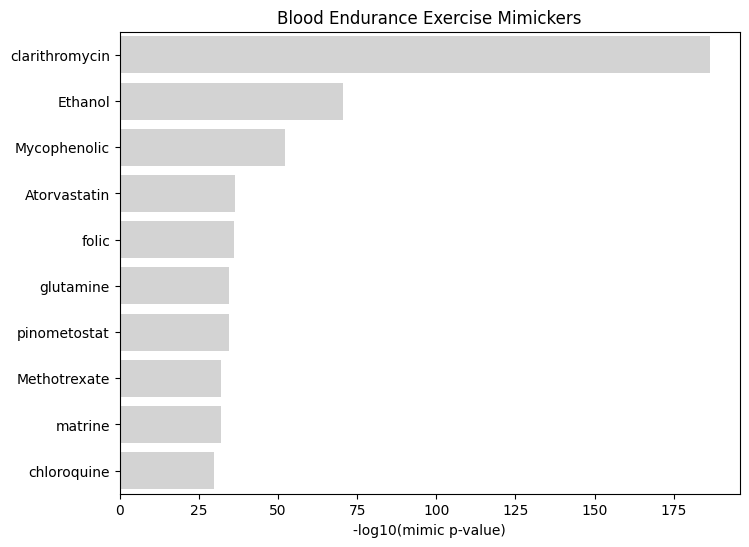

In [11]:
blood_endurance_drugs_cleaned = mimicker_bar_plot(blood_endurance_drugs, 'Blood Endurance Exercise Mimickers')

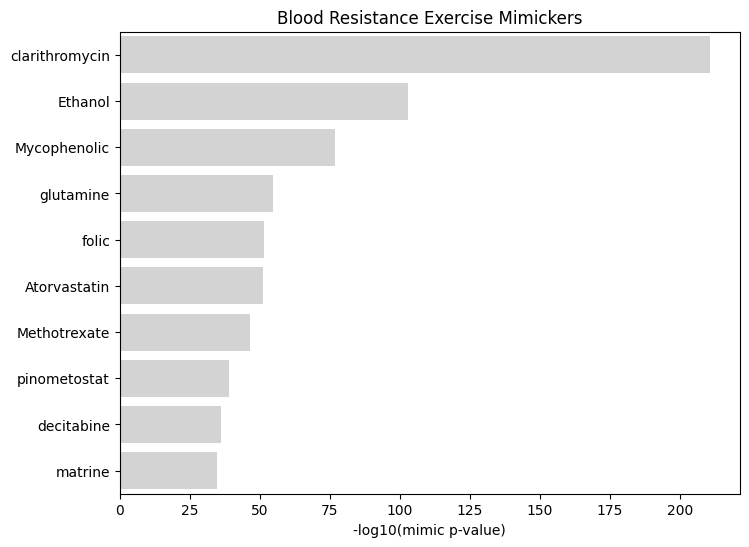

In [12]:
blood_resistance_drugs_cleaned = mimicker_bar_plot(blood_resistance_drugs, "Blood Resistance Exercise Mimickers" )

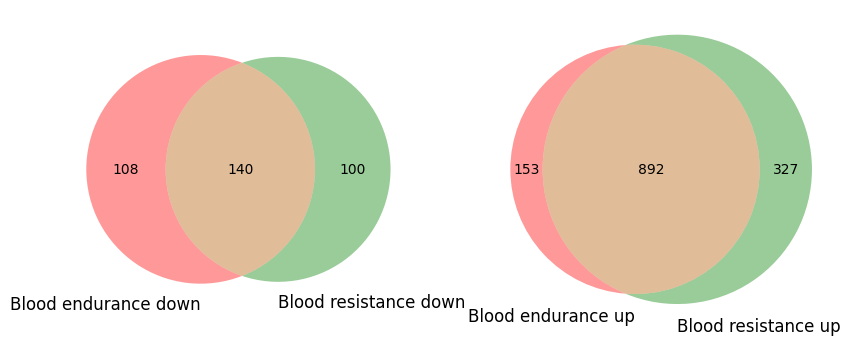

In [13]:
from matplotlib_venn import venn2
fig, axes = plt.subplots(ncols=2, nrows=1, figsize=(10,5))
venn2(subsets=(set(blood_endurance_down), set(blood_resistance_down)), set_labels=('Blood endurance down', 'Blood resistance down'), ax=axes[0])
venn2(subsets=(set(blood_endurance_up), set(blood_resistance_up)), set_labels=('Blood endurance up', 'Blood resistance up'), ax=axes[1])
plt.show()

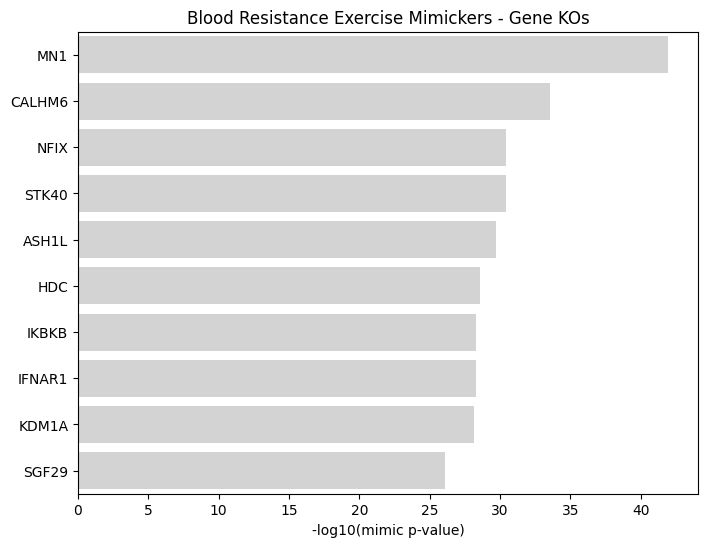

,perturbation,adjPvalueMimic,mimickerOverlap
9,MN1,1.08e-42,134
12,CALHM6,2.71e-34,296
17,NFIX,3.81e-31,149
18,STK40,4.08e-31,344
19,ASH1L,1.83e-30,326
23,HDC,2.49e-29,113
24,IKBKB,5.05e-29,123
25,IFNAR1,5.36e-29,121
22,KDM1A,6.56e-29,152
27,SGF29,7.94e-27,283


In [14]:
blood_resistance_kos_cleaned= mimicker_bar_plot_kos(blood_resistance_kos, 'Blood Resistance Exercise Mimickers - Gene KOs')

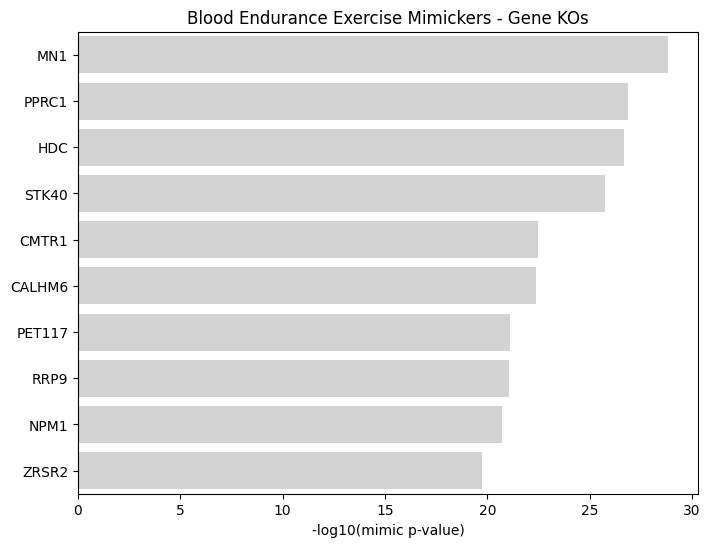

,perturbation,adjPvalueMimic,mimickerOverlap
12,MN1,1.43e-29,108
13,PPRC1,1.41e-27,52
14,HDC,2.10e-27,103
16,STK40,1.83e-26,306
18,CMTR1,3.29e-23,46
17,CALHM6,4.17e-23,246
21,PET117,7.59e-22,35
22,RRP9,9.30e-22,45
23,NPM1,1.93e-21,102
25,ZRSR2,1.78e-20,188


In [15]:
blood_endurance_kos_cleaned = mimicker_bar_plot_kos(blood_endurance_kos, 'Blood Endurance Exercise Mimickers - Gene KOs')

#### Overlap

In [16]:
from matplotlib_venn import venn2

def show_overlap(endurance_mimickers, resistance_mimickers, threshold, x_offset, y_offset):
    endurance = set(endurance_mimickers[(endurance_mimickers['adjPvalueMimic'] < threshold)]['term'])
    resistance = set(resistance_mimickers[(resistance_mimickers['adjPvalueMimic'] < threshold)]['term'])
    # Compute intersection
    overlap = [t.split('::')[0].upper() for t in (endurance & resistance)]
    term_overlap = (endurance & resistance)
    s1 = endurance_mimickers[endurance_mimickers['term'].isin(term_overlap)]
    s2 = resistance_mimickers[resistance_mimickers['term'].isin(term_overlap)]
    if 'moa' in s1.columns:
        joined = s1[['term','adjPvalueMimic','moa']].merge(s2[['term','adjPvalueMimic','moa']], how='inner', on='term', suffixes = ['_endurance','_resistance'])
        joined['pvalueProduct'] = joined['adjPvalueMimic_endurance'] * joined['adjPvalueMimic_resistance']
        joined = joined.sort_values('pvalueProduct', ascending=True)
        overlap_moa = ([row['term'].split('::')[0].upper() + f" ({re.sub(r'[|;]',',',str(row['moa_resistance']))})"
                    for _,row in joined.head(20).iterrows()
                        if pd.notna(row['moa_resistance'])])
        overlap_no_moa = ([row['term'].split('::')[0].upper()
                            for _,row in joined.head(20).iterrows()
                                if pd.isna(row['moa_resistance'])])
        overlap_text = "\n".join(sorted(overlap_moa + overlap_no_moa)) 
    else:
        joined = s1[['term','adjPvalueMimic']].merge(s2[['term','adjPvalueMimic']], how='inner', on='term', suffixes = ['_endurance','_resistance'])
        joined['pvalueProduct'] = joined['adjPvalueMimic_endurance'] * joined['adjPvalueMimic_resistance']
        joined = joined.sort_values('pvalueProduct', ascending=True)
        overlap_text = "\n".join(sorted([term.split('::')[0] for term in joined.head(20)['term']]))
    
    _, ax = plt.subplots(figsize=(5,5))
    v = venn2(subsets=(endurance, resistance), set_labels=('Endurance Mimickers', 'Resistance Mimickers'), set_colors=("#0C7BDC", "#FFC20A"), alpha=0.8)
    # Subset label font size
    for text in v.subset_labels:
        if text:
            text.set_fontsize(16)
    # Get intersection region center
    intersection_label = v.get_label_by_id('11')
    if intersection_label:
        x, y = intersection_label.get_position()
        intersection_label.set_fontsize(12)
        intersection_label.set_fontweight('bold')

        # Add annotation offset from intersection
        ax.annotate(
            overlap_text,
            xy=(x, y),                 # point to overlap
            xytext=(x + x_offset, y + y_offset), # text position
            fontsize=10,
            ha='left',
            va='center',
            bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8),
            arrowprops=dict(arrowstyle='->', lw=1, shrinkB=5)
        )
    plt.show()
    return overlap, overlap_text

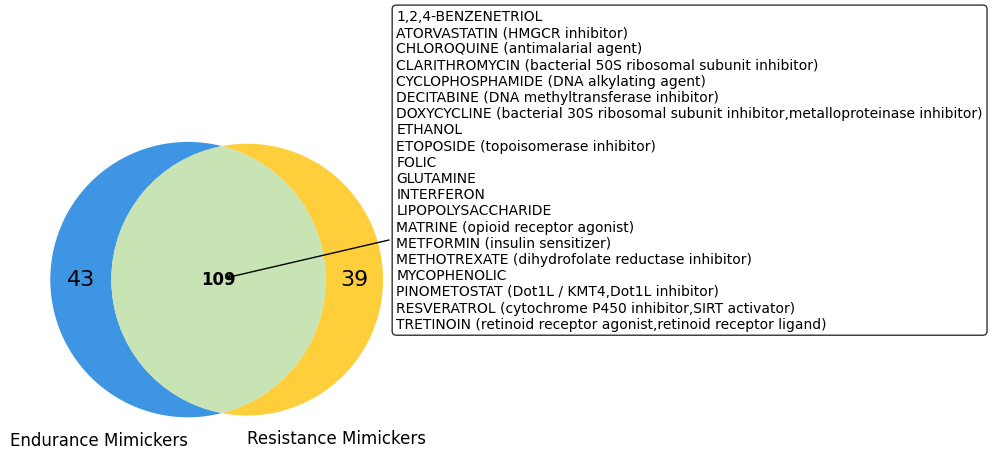

In [17]:
blood_drug_overlap = show_overlap(blood_endurance_drugs_cleaned,
                                  blood_resistance_drugs_cleaned,
                                  threshold=0.01,
                                  x_offset=0.65,
                                  y_offset=0.4)

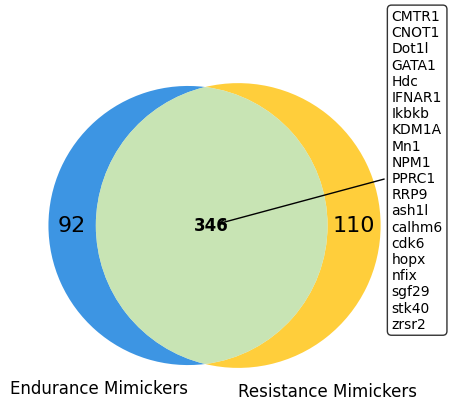

In [18]:
blood_ko_overlap,_ = show_overlap(blood_endurance_kos_cleaned, blood_resistance_kos_cleaned, threshold=0.05, x_offset=0.65, y_offset=0.2)

### Muscle

In [19]:
# Endurance
file_prefix = "muscle_ADUEndur.post_3.5_4_hr-ADUControl.post_3.5_4_hr-delta_delta"
muscle_endurance_up, muscle_endurance_down = get_gene_sets(file_prefix)
muscle_endurance_drugs, muscle_endurance_kos = get_mimickers(up=muscle_endurance_up,down=muscle_endurance_down)

In [20]:
# Resistance
file_prefix = "muscle_ADUResist.post_3.5_4_hr-ADUControl.post_3.5_4_hr-delta_delta"
muscle_resistance_up, muscle_resistance_down = get_gene_sets(file_prefix)
muscle_resistance_drugs,muscle_resistance_kos= get_mimickers(up=muscle_resistance_up,down=muscle_resistance_down)

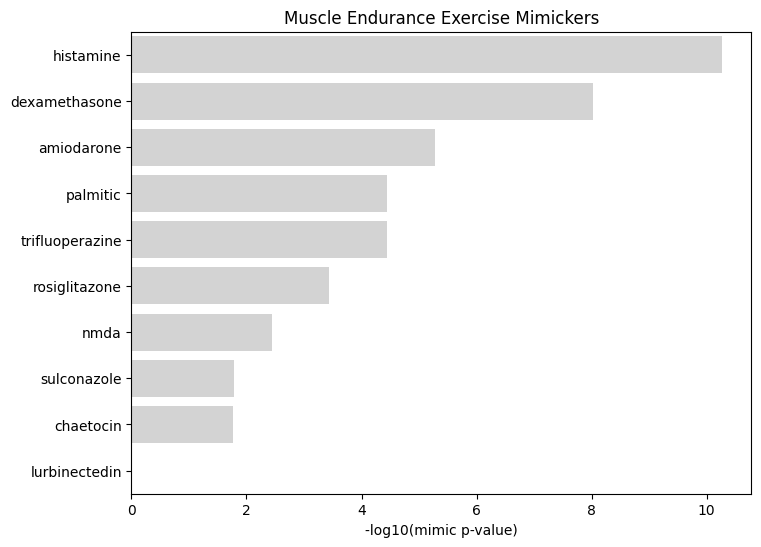

In [21]:
muscle_endurance_drugs_cleaned = mimicker_bar_plot(muscle_endurance_drugs, 'Muscle Endurance Exercise Mimickers')

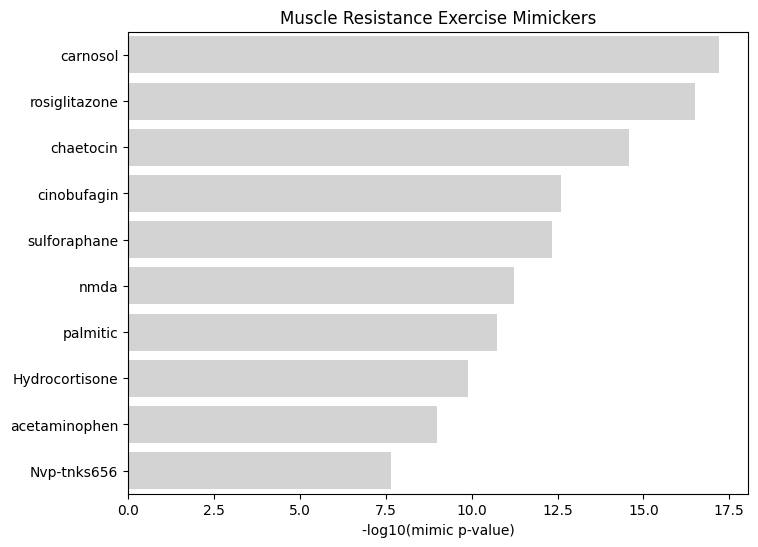

In [22]:
muscle_resistance_drugs_cleaned = mimicker_bar_plot(muscle_resistance_drugs, 'Muscle Resistance Exercise Mimickers')

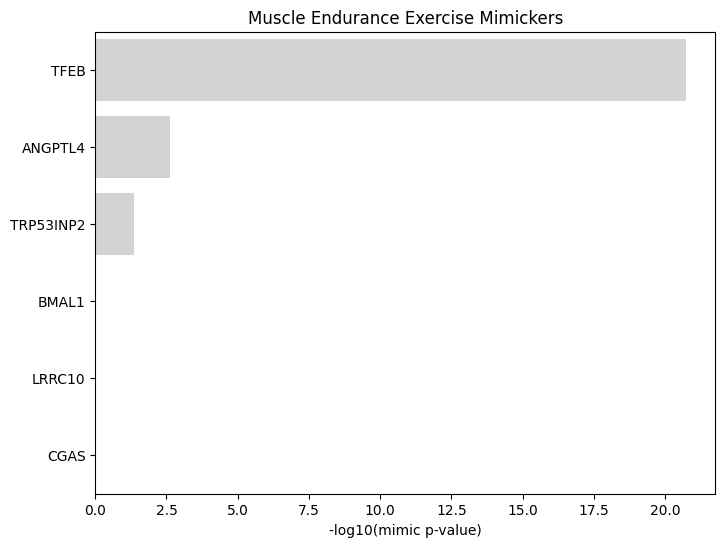

,perturbation,adjPvalueMimic,mimickerOverlap
0,TFEB,1.91e-21,99
6,ANGPTL4,2.46e-03,128
9,TRP53INP2,4.42e-02,57
15,BMAL1,1.00e+00,12
17,LRRC10,1.00e+00,29
18,CGAS,1.00e+00,30


In [23]:
muscle_endurance_kos_cleaned = mimicker_bar_plot_kos(muscle_endurance_kos, 'Muscle Endurance Exercise Mimickers')

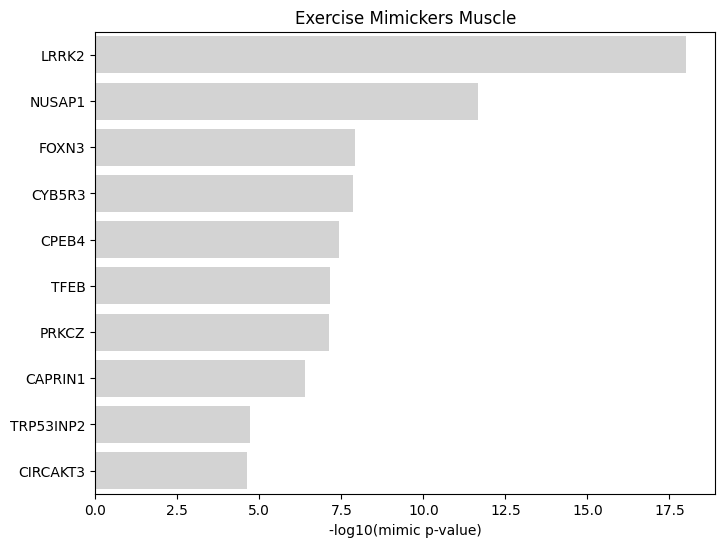

,perturbation,adjPvalueMimic,mimickerOverlap
0,LRRK2,1.01e-18,163
8,NUSAP1,2.11e-12,156
15,FOXN3,1.18e-08,87
18,CYB5R3,1.40e-08,252
21,CPEB4,3.77e-08,117
22,TFEB,6.92e-08,78
23,PRKCZ,7.47e-08,77
25,CAPRIN1,3.92e-07,247
36,TRP53INP2,1.97e-05,73
28,CIRCAKT3,2.36e-05,42


In [24]:
muscle_resistance_kos_cleaned = mimicker_bar_plot_kos(muscle_resistance_kos, 'Exercise Mimickers Muscle')

#### Overlap

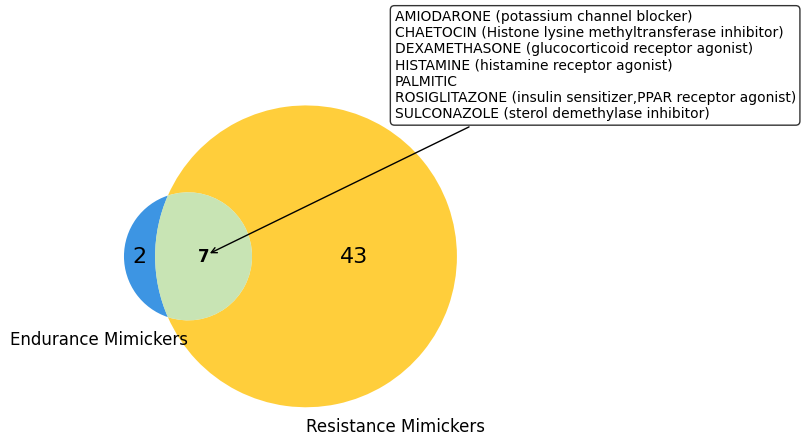

In [25]:
muscle_drug_overlap, muscle_drug_overlap_top20 = show_overlap(muscle_endurance_drugs_cleaned, 
                                                              muscle_resistance_drugs_cleaned, 
                                                              threshold=0.05, 
                                                              x_offset=0.7, 
                                                              y_offset=0.7)

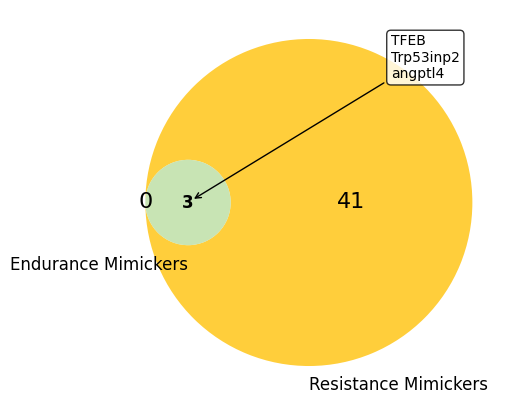

In [26]:
muscle_ko_overlap, muscle_ko_overlap_top20 = show_overlap(muscle_endurance_kos_cleaned,
                                                          muscle_resistance_kos_cleaned,
                                                          threshold=0.05,
                                                          x_offset=0.7,
                                                          y_offset=0.5)

### Adipose

In [27]:
# Endurance
file_prefix = "adipose_ADUEndur.post_3.5_4_hr-ADUControl.post_3.5_4_hr-delta_delta"
adipose_endurance_up, adipose_endurance_down = get_gene_sets(file_prefix)
adipose_endurance_drugs, adipose_endurance_kos = get_mimickers(up=adipose_endurance_up,down=adipose_endurance_down)

In [28]:
# Resistance
file_prefix = "adipose_ADUResist.post_3.5_4_hr-ADUControl.post_3.5_4_hr-delta_delta"
adipose_resistance_up, adipose_resistance_down = get_gene_sets(file_prefix)
adipose_resistance_drugs,adipose_resistance_kos= get_mimickers(up=adipose_resistance_up,down=adipose_resistance_down)

In [29]:
adipose_endurance_drugs_cleaned = mimicker_bar_plot(adipose_endurance_drugs, 'Muscle Endurance Exercise Mimickers')

empty dataframe


In [30]:
adipose_resistance_drugs_cleaned = mimicker_bar_plot(adipose_resistance_drugs, 'Muscle Resistance Exercise Mimickers')

empty dataframe


In [31]:
adipose_endurance_kos_cleaned = mimicker_bar_plot_kos(adipose_endurance_kos, 'Adipose Endurance Exercise Mimickers')

empty dataframe


In [32]:
adipose_resistance_kos_cleaned = mimicker_bar_plot_kos(adipose_resistance_kos, 'Adipose Resistance Exercise Mimickers')

empty dataframe
